<a href="https://colab.research.google.com/github/varshitfauzdar/AIH_Lab_work/blob/main/Lab5_AIH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Multiclass Classification
## Data Acquisition and Exploration

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

# Display settings
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/dermatology/dermatology.data"

columns = [
    "erythema",
    "scaling",
    "definite_borders",
    "itching",
    "koebner_phenomenon",
    "polygonal_papules",
    "follicular_papules",
    "oral_mucosal_involvement",
    "knee_and_elbow_involvement",
    "scalp_involvement",
    "family_history",
    "melanin_incontinence",
    "eosinophils_in_the_infiltrate",
    "PNL_infiltrate",
    "fibrosis_of_the_papillary_dermis",
    "exocytosis",
    "acanthosis",
    "hyperkeratosis",
    "parakeratosis",
    "clubbing_of_the_rete_ridges",
    "elongation_of_the_rete_ridges",
    "thinning_of_the_suprapapillary_epidermis",
    "spongiform_pustule",
    "munro_microabcess",
    "focal_hypergranulosis",
    "disappearance_of_the_granular_layer",
    "vacuolisation_and_damage_of_basal_layer",
    "spongiosis",
    "saw_tooth_appearance_of_retes",
    "follicular_horn_plug",
    "perifollicular_parakeratosis",
    "inflammatory_monoluclear_infiltrate",
    "band_like_infiltrate",
    "age",
    "class"
]

df = pd.read_csv(
    url,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (366, 35)


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,0,0,0,0,0,3,2,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,1,0,0,1,0,1,2,0,2,2,2,2,2,1,0,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,0,1,0,0,0,1,2,0,2,0,0,0,0,0,2,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,0,0,0,3,0,0,2,0,3,2,2,2,2,0,0,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,0,1,0,0,0,1,2,0,0,0,0,0,0,0,2,2,3,2,3,0,0,2,3,45.0,3


In [ ]:
summary_stats = df.describe()
summary_stats

,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_in_the_infiltrate,PNL_infiltrate,fibrosis_of_the_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_of_the_rete_ridges,elongation_of_the_rete_ridges,thinning_of_the_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_of_the_granular_layer,vacuolisation_and_damage_of_basal_layer,spongiosis,saw_tooth_appearance_of_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,class
count,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,358.000000,366.000000
mean,2.068306,1.795082,1.549180,1.366120,0.633880,0.448087,0.166667,0.377049,0.614754,0.519126,0.125683,0.404372,0.139344,0.546448,0.336066,1.368852,1.956284,0.527322,1.289617,0.663934,0.991803,0.633880,0.295082,0.363388,0.393443,0.464481,0.456284,0.953552,0.453552,0.103825,0.114754,1.866120,0.554645,36.296089,2.803279
std,0.664753,0.701527,0.907525,1.138299,0.908016,0.957327,0.570588,0.834147,0.982979,0.905639,0.331946,0.869818,0.411790,0.815451,0.853139,1.104418,0.712512,0.757116,0.917562,1.056829,1.162161,1.034924,0.670578,0.759721,0.849406,0.864899,0.954873,1.130172,0.954744,0.450433,0.488723,0.726108,1.105908,15.324557,1.597803
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,25.000000,1.000000
50%,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,35.000000,3.000000
75%,2.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,2.000000,2.000000,1.000000,2.000000,2.000000,2.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000,0.000000,0.000000,2.000000,0.000000,49.750000,4.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,1.000000,3.000000,2.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,75.000000,6.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   erythema                                  366 non-null    int64  
 1   scaling                                   366 non-null    int64  
 2   definite_borders                          366 non-null    int64  
 3   itching                                   366 non-null    int64  
 4   koebner_phenomenon                        366 non-null    int64  
 5   polygonal_papules                         366 non-null    int64  
 6   follicular_papules                        366 non-null    int64  
 7   oral_mucosal_involvement                  366 non-null    int64  
 8   knee_and_elbow_involvement                366 non-null    int64  
 9   scalp_involvement                         366 non-null    int64  
 10  family_history                        

In [ ]:
missing_val = df.isnull().sum().sum()
missing_val

np.int64(8)

In [ ]:
missing = df.isnull().sum()

missing = missing[missing > 0]

print("Columns with missing values:")
print(missing)

Columns with missing values:
age    8
dtype: int64


In [ ]:
median_age = df["age"].median()

df["age"] = df["age"].fillna(median_age)

print("Missing values after handling:")
print(df.isnull().sum().sum())

Missing values after handling:
0


In [ ]:
duplicate_count = df.duplicated().sum()
duplicate_count

np.int64(0)

In [ ]:
numeric_features = df.drop(columns=["class"]).select_dtypes(
    include=np.number
).columns

outlier_counts = {}

for column in numeric_features:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_counts[column] = len(outliers)

outlier_counts = pd.Series(outlier_counts)

print("Outlier count for each feature:")
print(outlier_counts)
print("Total outlier",outlier_counts.sum())

Outlier count for each feature:
erythema                                    151
scaling                                       0
definite_borders                              0
itching                                       0
koebner_phenomenon                           18
polygonal_papules                            69
follicular_papules                           33
oral_mucosal_involvement                     67
knee_and_elbow_involvement                   23
scalp_involvement                            16
family_history                               46
melanin_incontinence                         70
eosinophils_in_the_infiltrate                42
PNL_infiltrate                                7
fibrosis_of_the_papillary_dermis             54
exocytosis                                    0
acanthosis                                  156
hyperkeratosis                                5
parakeratosis                                 0
clubbing_of_the_rete_ridges                   0
elongati

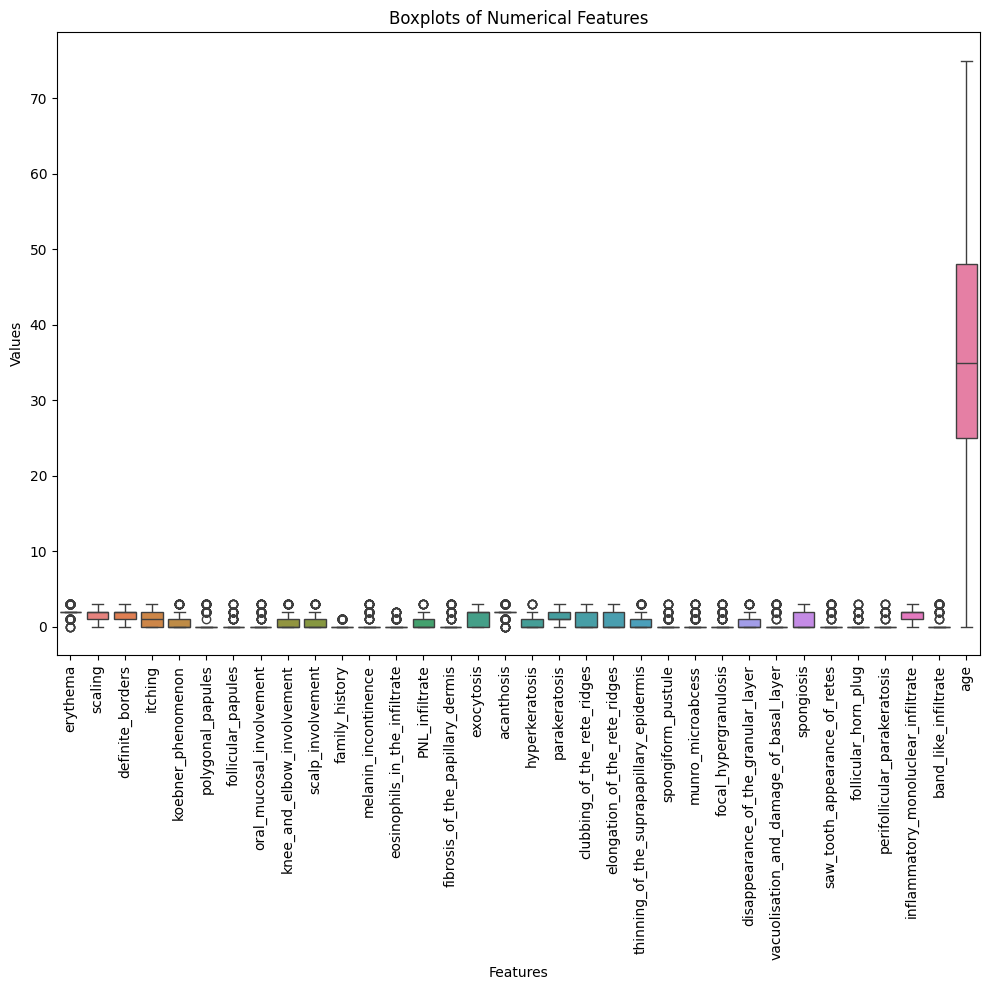

In [ ]:
plt.figure(figsize=(10,10))
sns.boxplot(data=df[numeric_features])

plt.xticks(rotation=90)
plt.title("Boxplots of Numerical Features")
plt.xlabel("Features")
plt.ylabel("Values")

plt.tight_layout()
plt.show()

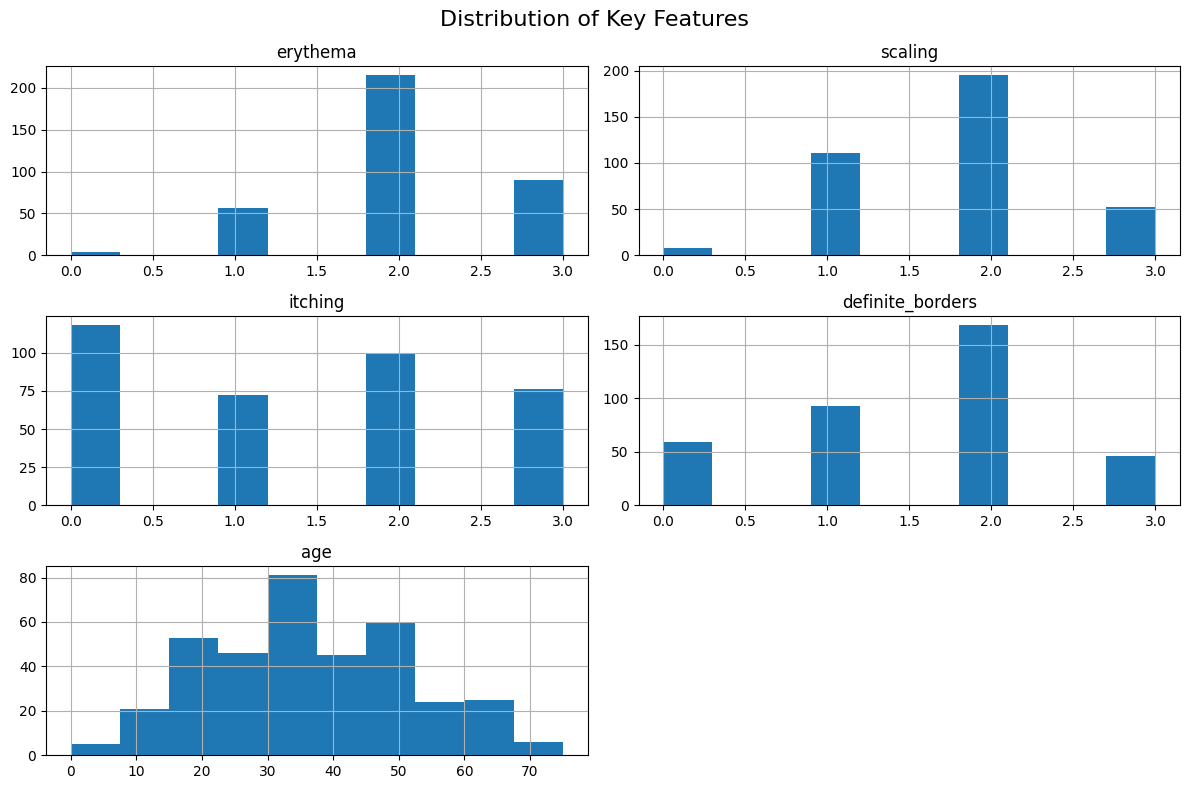

In [ ]:
key_features = [
    "erythema",
    "scaling",
    "itching",
    "definite_borders",
    "age"
]

df[key_features].hist(
    figsize=(12, 8),
    bins=10
)

plt.suptitle("Distribution of Key Features", fontsize=16)
plt.tight_layout()
plt.show()

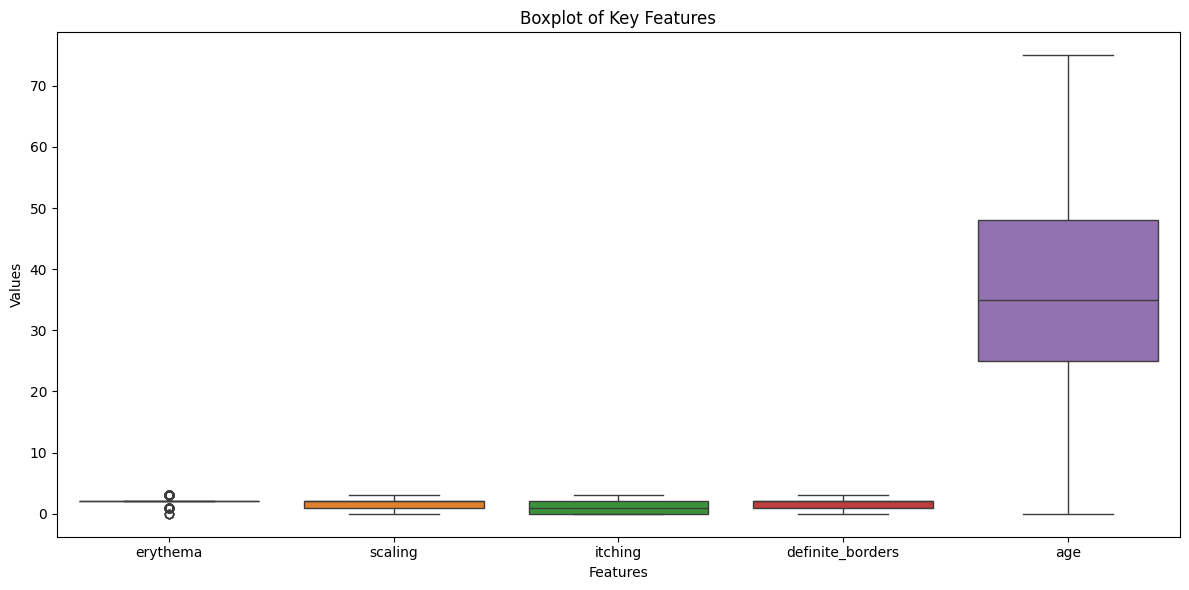

In [ ]:

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[key_features])

plt.title("Boxplot of Key Features")
plt.xlabel("Features")
plt.ylabel("Values")

plt.tight_layout()
plt.show()

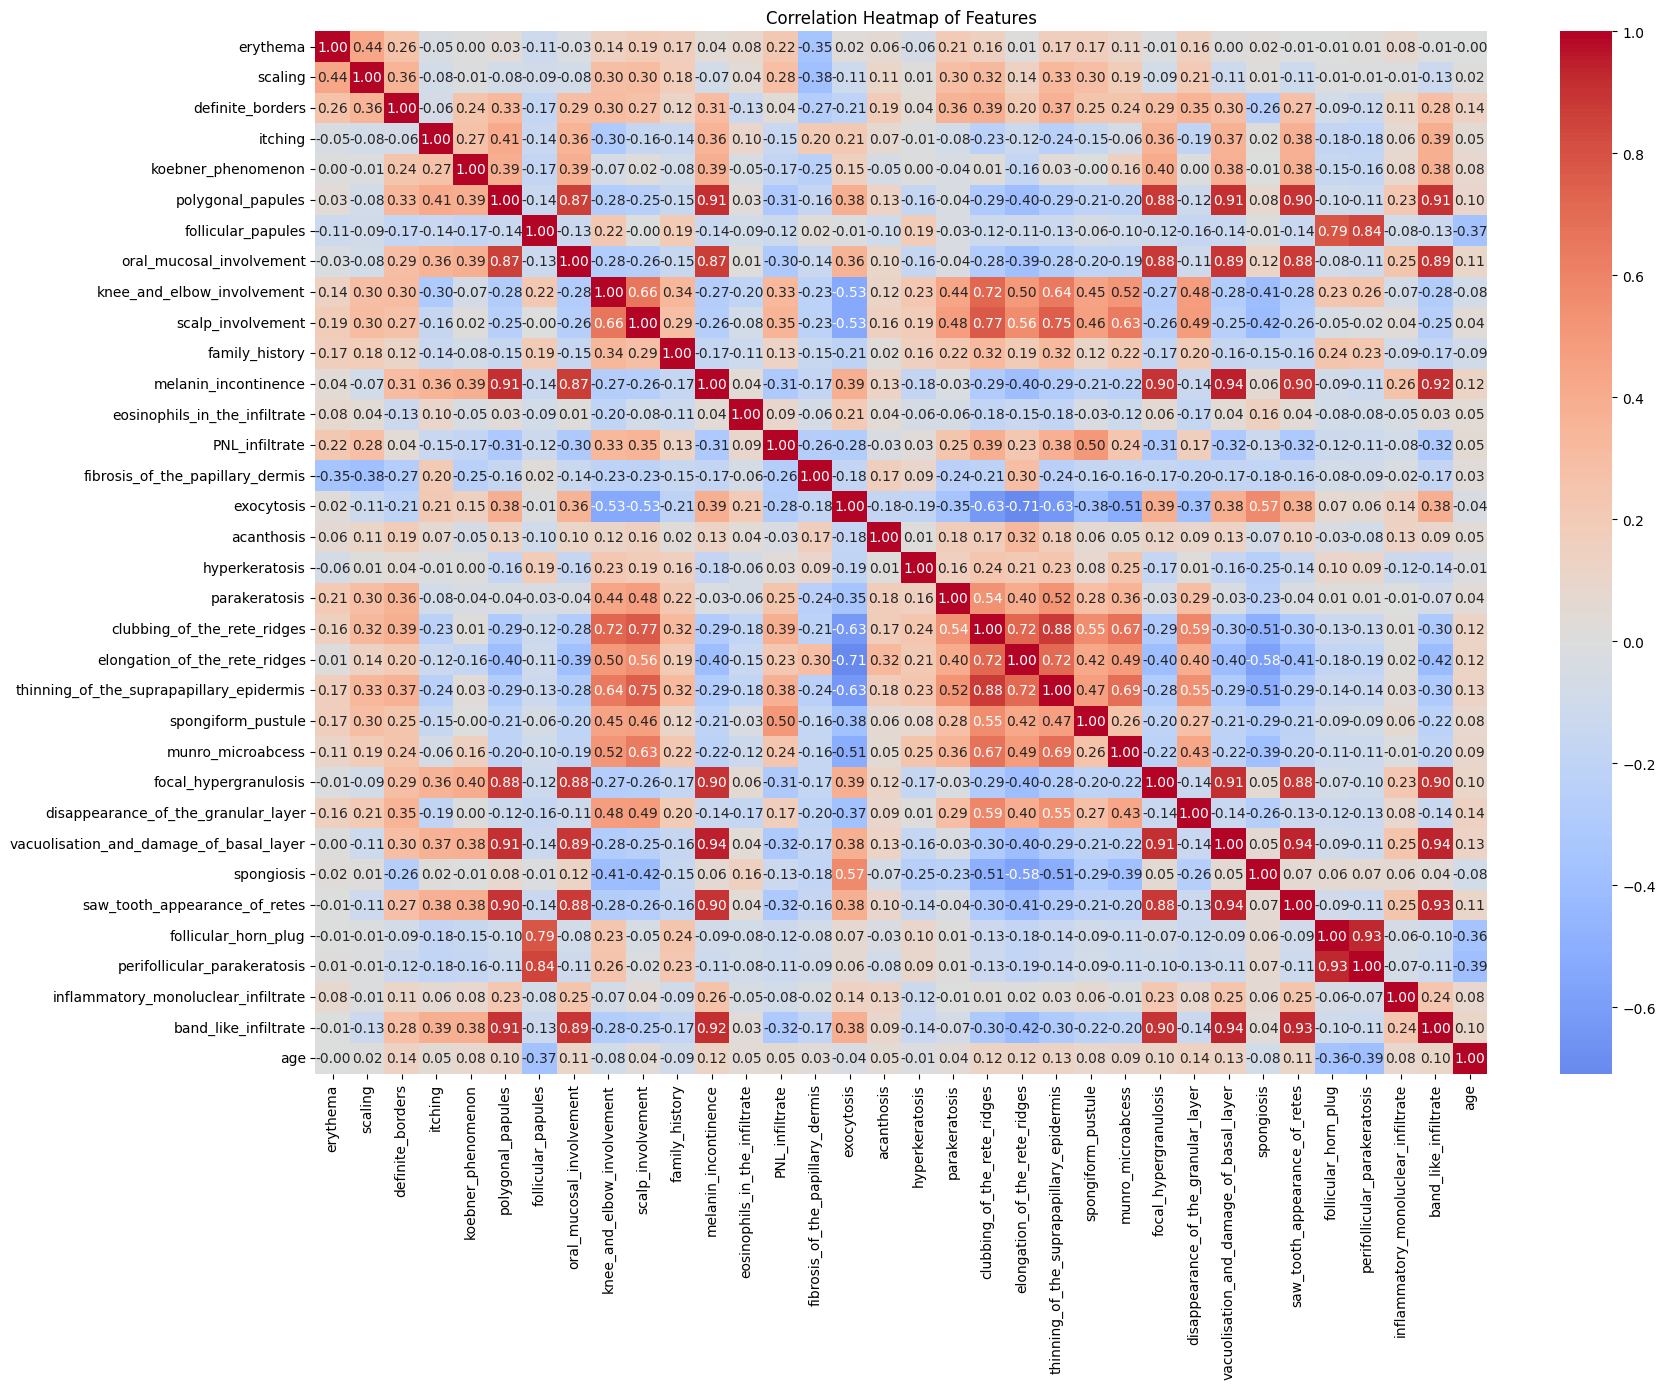

In [ ]:
correlation_matrix = df.drop(columns=["class"]).corr()

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    annot=True,
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap of Features")
plt.tight_layout()
plt.show()

In [ ]:
class_counts = df["class"].value_counts().sort_index()

print("Class distribution:")
print(class_counts)

Class distribution:
class
1    112
2     61
3     72
4     49
5     52
6     20
Name: count, dtype: int64


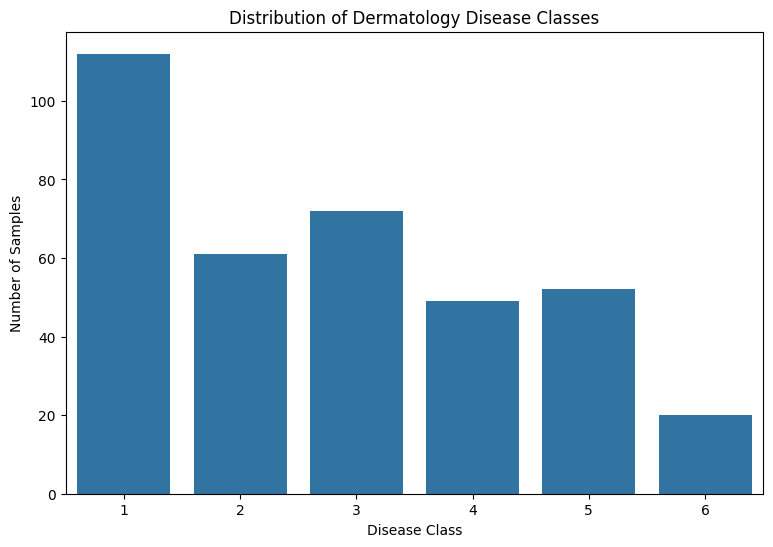

In [ ]:
plt.figure(figsize=(9, 6))

sns.countplot(
    data=df,
    x="class"
)

plt.title("Distribution of Dermatology Disease Classes")
plt.xlabel("Disease Class")
plt.ylabel("Number of Samples")

plt.show()

##  Data Preprocessing

In [ ]:

X = df.drop("class", axis=1)
y = df["class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget classes:")
print(sorted(y.unique()))

Features shape: (366, 34)
Target shape: (366,)

Feature columns:
['erythema', 'scaling', 'definite_borders', 'itching', 'koebner_phenomenon', 'polygonal_papules', 'follicular_papules', 'oral_mucosal_involvement', 'knee_and_elbow_involvement', 'scalp_involvement', 'family_history', 'melanin_incontinence', 'eosinophils_in_the_infiltrate', 'PNL_infiltrate', 'fibrosis_of_the_papillary_dermis', 'exocytosis', 'acanthosis', 'hyperkeratosis', 'parakeratosis', 'clubbing_of_the_rete_ridges', 'elongation_of_the_rete_ridges', 'thinning_of_the_suprapapillary_epidermis', 'spongiform_pustule', 'munro_microabcess', 'focal_hypergranulosis', 'disappearance_of_the_granular_layer', 'vacuolisation_and_damage_of_basal_layer', 'spongiosis', 'saw_tooth_appearance_of_retes', 'follicular_horn_plug', 'perifollicular_parakeratosis', 'inflammatory_monoluclear_infiltrate', 'band_like_infiltrate', 'age']

Target classes:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [ ]:

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

print("Original classes:")
print(label_encoder.classes_)

print("\nEncoded classes:")
print(np.unique(y_encoded))

Original classes:
[1 2 3 4 5 6]

Encoded classes:
[0 1 2 3 4 5]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (292, 34)
Testing set: (74, 34)


In [ ]:
print("Training class distribution:")
print(pd.Series(y_train).value_counts(normalize=True).sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts(normalize=True).sort_index())

Training class distribution:
0    0.304795
1    0.167808
2    0.195205
3    0.133562
4    0.143836
5    0.054795
Name: proportion, dtype: float64

Testing class distribution:
0    0.310811
1    0.162162
2    0.202703
3    0.135135
4    0.135135
5    0.054054
Name: proportion, dtype: float64


In [ ]:
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)

print("\nFirst 5 rows of scaled training data:")
print(X_train_scaled[:5])

Original training shape: (292, 34)
Scaled training shape: (292, 34)

First 5 rows of scaled training data:
[[-0.07466199  1.68231685  0.47240405  1.43048804  2.64055903  1.64897328
  -0.29148599  1.92481686 -0.62839093 -0.57487109 -0.39261966  1.84566397
  -0.33287436 -0.66904287 -0.39476692  1.47730234  0.07360462 -0.70761653
  -1.4336383  -0.62908464 -0.8509907  -0.60711112 -0.44244015 -0.47800907
   3.03544153  1.79841481  1.66262324  0.02121534  1.62472075 -0.2377448
  -0.23371278  0.20500611  1.31524484 -0.62277342]
 [-0.07466199  0.2827826  -0.62237359  1.43048804 -0.6924809  -0.46286969
  -0.29148599 -0.45170121 -0.62839093 -0.57487109 -0.39261966 -0.46735697
  -0.33287436 -0.66904287  3.06339126 -1.25290198  0.07360462  0.60846007
  -1.4336383  -0.62908464  1.72848284 -0.60711112 -0.44244015 -0.47800907
  -0.46791391 -0.52520079 -0.48080275 -0.86376725 -0.46984198 -0.2377448
  -0.23371278  0.20500611 -0.50060147  0.98708706]
 [-0.07466199  0.2827826   0.47240405 -1.23003749  1.

In [ ]:
scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

print("Mean of scaled features:")
print(scaled_df.mean().round(2))

print("\nStandard deviation of scaled features:")
print(scaled_df.std().round(2))

Mean of scaled features:
erythema                                    0.0
scaling                                     0.0
definite_borders                           -0.0
itching                                    -0.0
koebner_phenomenon                         -0.0
polygonal_papules                           0.0
follicular_papules                          0.0
oral_mucosal_involvement                   -0.0
knee_and_elbow_involvement                 -0.0
scalp_involvement                          -0.0
family_history                              0.0
melanin_incontinence                       -0.0
eosinophils_in_the_infiltrate              -0.0
PNL_infiltrate                             -0.0
fibrosis_of_the_papillary_dermis            0.0
exocytosis                                 -0.0
acanthosis                                  0.0
hyperkeratosis                             -0.0
parakeratosis                               0.0
clubbing_of_the_rete_ridges                -0.0
elongation_of_t

## Train 5 multiclass models:

Logistic Regression<br>
KNN<br>
Random Forest<br>
SVM<br>
Decision Tree<br>

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    )
}

print("Models created successfully!")

Models created successfully!


In [ ]:
trained_models = {}

for name, model in models.items():

    # Train model
    model.fit(X_train_scaled, y_train)

    # Store trained model
    trained_models[name] = model

    print(f"{name} trained successfully!")

Logistic Regression trained successfully!
KNN trained successfully!
Random Forest trained successfully!
SVM trained successfully!
Decision Tree trained successfully!


In [ ]:
predictions = {}

for name, model in trained_models.items():

    y_pred = model.predict(X_test_scaled)

    predictions[name] = y_pred

    print(f"{name} predictions generated.")

Logistic Regression predictions generated.
KNN predictions generated.
Random Forest predictions generated.
SVM predictions generated.
Decision Tree predictions generated.


In [ ]:
accuracy_results = {}

for name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)

    accuracy_results[name] = accuracy

accuracy_df = pd.DataFrame(
    list(accuracy_results.items()),
    columns=["Model", "Accuracy"]
)

accuracy_df = accuracy_df.sort_values(
    by="Accuracy",
    ascending=False
)

accuracy_df

,Model,Accuracy
3,SVM,0.972973
0,Logistic Regression,0.959459
2,Random Forest,0.959459
4,Decision Tree,0.959459
1,KNN,0.905405


In [ ]:
class_names = [
    "Psoriasis",
    "Seboreic dermatitis",
    "Lichen planus",
    "Pityriasis rosea",
    "Chronic dermatitis",
    "Pityriasis rubra pilaris"
]

for name, y_pred in predictions.items():

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=class_names,
            zero_division=0
        )
    )


Logistic Regression
                          precision    recall  f1-score   support

               Psoriasis       1.00      1.00      1.00        23
     Seboreic dermatitis       1.00      0.83      0.91        12
           Lichen planus       1.00      0.93      0.97        15
        Pityriasis rosea       0.77      1.00      0.87        10
      Chronic dermatitis       1.00      1.00      1.00        10
Pityriasis rubra pilaris       1.00      1.00      1.00         4

                accuracy                           0.96        74
               macro avg       0.96      0.96      0.96        74
            weighted avg       0.97      0.96      0.96        74


KNN
                          precision    recall  f1-score   support

               Psoriasis       1.00      0.96      0.98        23
     Seboreic dermatitis       0.80      0.67      0.73        12
           Lichen planus       1.00      0.93      0.97        15
        Pityriasis rosea       0.64      0.90 

In [ ]:
results = []

for name, y_pred in predictions.items():

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,SVM,0.972973,0.977477,0.972973,0.972973
1,Logistic Regression,0.959459,0.968815,0.959459,0.960642
2,Random Forest,0.959459,0.960688,0.959459,0.959543
3,Decision Tree,0.959459,0.964619,0.959459,0.959392
4,KNN,0.905405,0.919305,0.905405,0.908094


In [ ]:
roc_auc_results = {}

for name, y_prob in probabilities.items():

    auc_score = roc_auc_score(
        y_test,
        y_prob,
        multi_class="ovr",
        average="weighted"
    )

    roc_auc_results[name] = auc_score

    print(f"{name}: ROC-AUC = {auc_score:.4f}")

Logistic Regression: ROC-AUC = 0.9991
KNN: ROC-AUC = 0.9871
Random Forest: ROC-AUC = 0.9985
SVM: ROC-AUC = 0.9983
Decision Tree: ROC-AUC = 0.9772


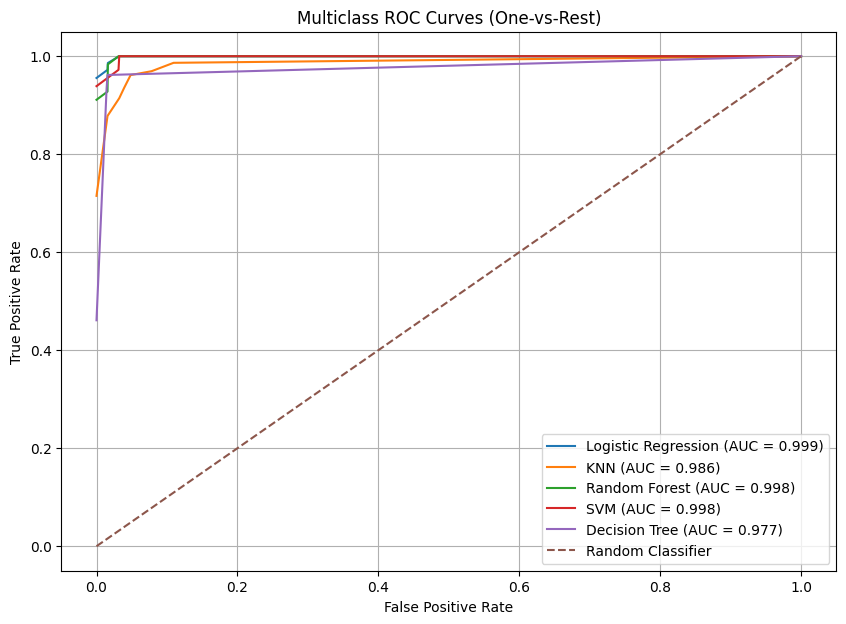

In [ ]:
from sklearn.preprocessing import label_binarize

# Convert test labels into binary form
y_test_binarized = label_binarize(
    y_test,
    classes=np.arange(6)
)

plt.figure(figsize=(10, 7))

for name, y_prob in probabilities.items():

    # Calculate macro-average ROC-AUC
    auc_score = roc_auc_score(
        y_test_binarized,
        y_prob,
        average="macro",
        multi_class="ovr"
    )

    # Calculate macro-average ROC curve
    fpr = dict()
    tpr = dict()

    for i in range(6):
        fpr[i], tpr[i], _ = roc_curve(
            y_test_binarized[:, i],
            y_prob[:, i]
        )

    # Interpolate all FPR points
    all_fpr = np.unique(
        np.concatenate([fpr[i] for i in range(6)])
    )

    mean_tpr = np.zeros_like(all_fpr)

    for i in range(6):
        mean_tpr += np.interp(
            all_fpr,
            fpr[i],
            tpr[i]
        )

    mean_tpr /= 6

    plt.plot(
        all_fpr,
        mean_tpr,
        label=f"{name} (AUC = {auc_score:.3f})"
    )

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves (One-vs-Rest)")
plt.legend()
plt.grid()

plt.show()